# Sudoku Solver with Simulated Annealing (SA) and Variable Neighborhood Search (VNS)
This notebook explores techniques for solving Sudoku puzzles using heuristic methods. The project combines:
- **Simulated Annealing (SA)**: A probabilistic method for escaping local minima.
- **VNS-style perturbations**: Optional enhancements that help the search jump to new neighborhoods.
- **ILP Solver**: Used as a comparison benchmark.

We'll walk through each component: cost evaluation, swap logic, solver loop, and benchmarking.

## Notebook Structure
1. [Cost Evaluation](#Cost-Evaluation)
2. [Swap Logic and Helper Functions](#Swap-and-Helper-Functions)
3. [Simulated Annealing Solver](#Simulated-Annealing)
4. [Puzzle Generator](#Puzzle-Generation)
5. [Benchmarking with ILP](#Benchmarking)
6. [Visualization](#Visualization)
7. [Demo & Config Testing](#Demo)


In [1]:
import random
import math
import matplotlib.pyplot as plt
import time
import copy
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB

## Cost Evaluation
This function counts conflicts in rows and columns.

In [2]:
def evaluate(grid):
    size = len(grid)
    cost = 0
    for row in grid:
        cost += size - len(set(row))
    for col in zip(*grid):
        cost += size - len(set(col))
    return cost

def get_conflicted_cells(grid, fixed_cells):
    size = len(grid)
    conflicts = set()
    for r in range(size):
        seen = {}
        for c in range(size):
            val = grid[r][c]
            if val in seen:
                if (r, c) not in fixed_cells:
                    conflicts.add((r, c))
                if (r, seen[val]) not in fixed_cells:
                    conflicts.add((r, seen[val]))
            else:
                seen[val] = c
    for c in range(size):
        seen = {}
        for r in range(size):
            val = grid[r][c]
            if val in seen:
                if (r, c) not in fixed_cells:
                    conflicts.add((r, c))
                if (seen[val], c) not in fixed_cells:
                    conflicts.add((seen[val], c))
            else:
                seen[val] = r
    return list(conflicts)


## Swap and Helper Functions
Functions for identifying non-fixed cells and swapping them.

In [3]:
def get_non_fixed_cells_in_box(grid, cell, fixed_cells):
    size = len(grid)
    n = int(size ** 0.5)
    r0 = (cell[0] // n) * n
    c0 = (cell[1] // n) * n
    return [(r, c) for r in range(r0, r0 + n) for c in range(c0, c0 + n)
            if (r, c) != cell and (r, c) not in fixed_cells]

def perform_swap(grid, cell1, cell2):
    grid[cell1[0]][cell1[1]], grid[cell2[0]][cell2[1]] = \
        grid[cell2[0]][cell2[1]], grid[cell1[0]][cell1[1]]

def conflict_driven_swap(grid, fixed_cells, temperature, prev_cost, candidates, p_conflict=None, initial_temp=None, VNS = True):
    
    size = len(grid)
        
    if p_conflict is None and initial_temp is not None:
        p_conflict = max(0.1, min(0.9, 1 - temperature / initial_temp))

    if not VNS or random.random() > p_conflict:
        mutable_cells = [(r, c) for r in range(size) for c in range(size) if (r, c) not in fixed_cells]
        cell1 = random.choice(mutable_cells)
        subgrid_peers = get_non_fixed_cells_in_box(grid, cell1, fixed_cells)
        if not subgrid_peers:
            return prev_cost, False
        cell2 = random.choice(subgrid_peers)
        perform_swap(grid, cell1, cell2)
        new_cost = evaluate(grid)
        delta = new_cost - prev_cost
        if delta <= 0 or random.random() < math.exp(-delta / temperature):
            return new_cost, True
        else:
            perform_swap(grid, cell1, cell2)
            return prev_cost, False

    conflicted = get_conflicted_cells(grid, fixed_cells)
    if not conflicted:
        return prev_cost, True
    

    cell1 = random.choice(conflicted)
    subgrid_peers = get_non_fixed_cells_in_box(grid, cell1, fixed_cells)

    valid_peers = [cell2 for cell2 in subgrid_peers
                    if grid[cell1[0]][cell1[1]] in candidates.get(cell2, set()) and
                    grid[cell2[0]][cell2[1]] in candidates.get(cell1, set())]

    if not valid_peers:
        return prev_cost, False

    cell2 = random.choice(valid_peers)
    perform_swap(grid, cell1, cell2)
    new_cost = evaluate(grid)
    delta = new_cost - prev_cost

    if delta <= 0 or random.random() < math.exp(-delta / temperature):
        return new_cost, True
    else:
        perform_swap(grid, cell1, cell2)
        return prev_cost, False

## Initialization
Helper to prepare data.

In [4]:
def get_hint_candidates(grid):
    size = len(grid)
    n = int(size ** 0.5)
    candidates = {}
    for r in range(size):
        for c in range(size):
            if grid[r][c] != 0:
                continue
            row_vals = set(grid[r])
            col_vals = set(grid[i][c] for i in range(size))
            box_vals = set()
            r0 = (r // n) * n
            c0 = (c // n) * n
            for i in range(r0, r0 + n):
                for j in range(c0, c0 + n):
                    box_vals.add(grid[i][j])
            used = row_vals | col_vals | box_vals
            candidates[(r, c)] = set(range(1, size + 1)) - used
    return candidates

def initialize_solution(grid, fixed_cells, candidates, constructive = True):
    size = len(grid)
    n = int(size ** 0.5)
    new_grid = copy.deepcopy(grid)

    for box_row in range(0, size, n):
        for box_col in range(0, size, n):
            nums = set(range(1, size + 1))
            for r in range(box_row, box_row + n):
                for c in range(box_col, box_col + n):
                    if (r, c) in fixed_cells:
                        nums.discard(grid[r][c])
            empty_cells = [(r, c) for r in range(box_row, box_row + n)
                                      for c in range(box_col, box_col + n)
                                      if (r, c) not in fixed_cells]
            random.shuffle(empty_cells)
            for r, c in empty_cells:
                if constructive:
                    options = list(candidates.get((r, c), nums) & nums)
                else:
                    options = list(nums)
                if options:
                    chosen = random.choice(options)
                    new_grid[r][c] = chosen
                    nums.discard(chosen)
                else:
                    chosen = random.choice(list(nums))
                    new_grid[r][c] = chosen
                    nums.discard(chosen)
    return new_grid

## Simulated Annealing
The main solver logic using SA (with optional VNS-style jumps).

In [5]:
def run_simulated_annealing(initial_grid, fixed_cells, alpha=0.99, max_time=5.0, P=0.55, verbose=False, VNS = True, constructive_candidate = True):
    size = len(initial_grid)
    candidates = get_hint_candidates(initial_grid)
    grid = initialize_solution(initial_grid, fixed_cells, candidates, constructive = constructive_candidate)
    current_cost = evaluate(grid)
    # Scale temperature based on initial cost for better exploration
    time_costs = [(0.0, current_cost)]
    best_cost = current_cost
    last_improvement_iter = 0
    start_time = time.process_time()
    iteration = 0
    best_cost = current_cost
    if current_cost == 0:
        return grid, current_cost, iteration, time.process_time() - start_time, np.array(time_costs)
    initial_temp = current_cost*0.5
    temperature = initial_temp
    if verbose:
        print(f"Initial cost: {current_cost}, scaled initial_temp: {initial_temp:.2f}")

    while True:
        current_time = time.process_time()
        elapsed = current_time - start_time
        time_costs.append((elapsed, current_cost))
        if elapsed >= max_time:
            break

        current_cost, moved = conflict_driven_swap(grid, fixed_cells, temperature, current_cost, candidates, initial_temp=initial_temp, VNS = VNS)
        temperature *= alpha
        if current_cost == 0:
            break
        reheat_threshold = size**2*current_cost**2
        if iteration - last_improvement_iter >= reheat_threshold:
            if verbose:
                print(f"Reheated at temperature {temperature:.4f} to temperature {P * best_cost:.4f}")
            temperature = P * best_cost
            last_improvement_iter = iteration
            
        iteration += 1
        if moved:
            if current_cost < best_cost:
                best_cost = current_cost
                last_improvement_iter = iteration

    

    return grid, current_cost, iteration, time.process_time() - start_time, np.array(time_costs)

## Puzzle Generation
Generate random puzzles with solutions for testing.

In [6]:
def generate_and_save_solutions(n=16, count=10, timeout=180.0, output="precomputed_16x16.csv"):
    saved = []
    attempts = 0

    while len(saved) < count:
        print(f"Attempting solution {len(saved)+1}...")
        empty = [[0] * n for _ in range(n)]
        fixed = set()
        solution, cost, _, _, _ = run_simulated_annealing(empty, fixed, max_time=timeout)

        if cost == 0:
            flat = ' '.join(str(cell) for row in solution for cell in row)
            saved.append(flat)
            print(f"✓ Saved (total: {len(saved)})")
        else:
            print(f"✗ Failed (cost = {cost})")
        attempts += 1

    df = pd.DataFrame({"solution": saved})
    df.to_csv(output, index=False)
    print(f" Done. {len(saved)} solutions saved after {attempts} attempts.")

## Additional Puzzle Generator
More flexible generation for random grid creation.

In [8]:
def generate_random_puzzle(size=9, num_clues=None, seed = None):
    n = int(size ** 0.5)
    assert n * n == size, "Size must be a perfect square (e.g., 4, 9, 16)"
    if seed != None:
        random.seed(seed)
    
    try:
        df = pd.read_csv(f"precomputed_{size}x{size}.csv")
        if seed == None:
            raw = df.sample(n=1).iloc[0]['solution']
        else:
            raw = df.sample(n=1, random_state = seed).iloc[0]['solution']
        full_solution = string_to_grid(raw, size=size, separator=' ')
    except Exception:
        # Fallback to generating one
        print("No precomputed solution found, generating one from scratch...")
        empty_grid = [[0] * size for _ in range(size)]
        fixed = set()
        full_solution, cost, _, _ = run_simulated_annealing(empty_grid, fixed, max_time=5.0)
        if cost != 0:
            raise RuntimeError("Failed to generate a valid full solution.")

    puzzle = copy.deepcopy(full_solution)
    total_cells = size * size
    if num_clues is None:
        num_clues = random.randint(size * 2, total_cells)
    cells = [(i, j) for i in range(size) for j in range(size)]
    random.shuffle(cells)
    for i, j in cells[:total_cells - num_clues]:
        puzzle[i][j] = 0

    return puzzle, full_solution

## Benchmarking
Use ILP to compare results against heuristic solutions.

In [9]:
def string_to_grid(s, size=9, separator=''):
    if separator:
        tokens = s.split(separator)
    else:
        width = len(str(size))
        tokens = [int(s[i:i+width]) for i in range(0, len(s), width)]
    return [[int(tokens[i * size + j]) for j in range(size)] for i in range(size)]

def grid_to_string(grid):
    return ''.join(str(cell) for row in grid for cell in row)

def benchmark_from_csv(path, n=100):
    df = pd.read_csv(path)
    sample = df.sample(n, random_state=42)
    solved = 0
    matched = 0
    total_time = 0
    times = []

    for i, row in sample.iterrows():
        puzzle = string_to_grid(row['puzzle'])
        expected = row['solution']
        fixed = {(i, j) for i in range(9) for j in range(9) if puzzle[i][j] != 0}

        result, cost, iterations, duration, _ = run_simulated_annealing(puzzle, fixed)
        result_string = grid_to_string(result)

        if cost == 0:
            solved += 1
        if result_string == expected:
            matched += 1

        total_time += duration
        times.append(duration)

        #if i % 1000 == 0:
            #print(f"{i} puzzles tested...")
    q1 = np.percentile(times, 25)
    q3 = np.percentile(times, 75)

    print(f"Solved (cost == 0): {solved}/{n}")
    print(f"Matched expected solution: {matched}/{n}")
    print(f"Average time: {total_time/n:.4f}s")
    print(f"Max time: {max(times):.4f}s")
    print(f"Min time: {min(times):.4f}s")
    print(f"1st Quartile (Q1): {q1:.4f}s")
    print(f"3rd Quartile (Q3): {q3:.4f}s")
    return solved, matched, total_time / n

def benchmark_all_configs_with_ilp_from_csv(path, n=100):
    df = pd.read_csv(path)
    sample = df.sample(n, random_state=42)

    configs = [
        {"label": "SA", "VNS": False, "constructive_candidate": False, "solver": "SA"},
        {"label": "SA+Greedy",    "VNS": False, "constructive_candidate": True,  "solver": "SA"},
        {"label": "VNS-SA hybrid",    "VNS": True,  "constructive_candidate": False, "solver": "SA"},
        {"label": "VNS-SA hybrid\n+Greedy",       "VNS": True,  "constructive_candidate": True,  "solver": "SA"},
        {"label": "ILP Solver",              "solver": "ILP"},
    ]

    results = []

    for config in configs:
        solved = 0
        matched = 0
        total_time = 0
        times = []

        print(f"Running benchmark: {config['label']}")

        for i, row in sample.iterrows():
            puzzle = string_to_grid(row['puzzle'])
            expected = row['solution']

            if config["solver"] == "SA":
                fixed = {(i, j) for i in range(9) for j in range(9) if puzzle[i][j] != 0}
                result, cost, _, duration, _ = run_simulated_annealing(
                    puzzle,
                    fixed,
                    VNS=config["VNS"],
                    constructive_candidate=config["constructive_candidate"],
                    max_time=10,
                    verbose=False
                )
            else:  # ILP
                result, cost, duration, _ = solve_with_ilp(puzzle, time_limit=10)

            result_string = grid_to_string(result)

            if cost == 0:
                solved += 1
                total_time += duration
                times.append(duration)
            if result_string == expected:
                matched += 1

        q1 = np.percentile(times, 25)
        q3 = np.percentile(times, 75)

        results.append({
            "Configuration": config["label"],
            "Solved (cost == 0)": f"{solved}/{n}",
            "Matched Solution": f"{matched}/{n}",
            "Avg Time (s)": total_time / len(times),
            "Min Time (s)": min(times),
            "Max Time (s)": max(times),
            "Q1 Time (s)": q1,
            "Q3 Time (s)": q3
        })

    return pd.DataFrame(results)

def plot_benchmark_table(df, save_path=None):
    fig, ax = plt.subplots(figsize=(14, 0.7 * len(df) + 2))
    ax.axis('off')  # Hide axes

    # Round numeric columns for display
    display_df = df.copy()
    for col in display_df.columns:
        if display_df[col].dtype == float:
            display_df[col] = display_df[col].map("{:.4f}".format)

    # Create the table
    table = ax.table(
        cellText=display_df.values,
        colLabels=display_df.columns,
        cellLoc='center',
        loc='center',
        bbox=[0, 0, 1, 1]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1.2, 1.5)

    # Style the header and rows
    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#40466e')
        elif row % 2 == 0:
            cell.set_facecolor('#f1f1f2')

    plt.title("Sudoku Solver Benchmark Comparison 9x9", fontsize=16, weight='bold', pad=20)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved table to: {save_path}")
    else:
        plt.show()

In [10]:
def solve_with_ilp(grid, time_limit=60):
    size = len(grid)
    n = int(size ** 0.5)
    model = gp.Model("sudoku")
    model.setParam('OutputFlag', 0)
    model.setParam('TimeLimit', time_limit)

    x = model.addVars(size, size, size, vtype=GRB.BINARY, name="x")

    for i in range(size):
        for j in range(size):
            if grid[i][j] != 0:
                model.addConstr(x[i, j, grid[i][j] - 1] == 1)

    for i in range(size):
        for j in range(size):
            model.addConstr(gp.quicksum(x[i, j, k] for k in range(size)) == 1)

    for i in range(size):
        for k in range(size):
            model.addConstr(gp.quicksum(x[i, j, k] for j in range(size)) == 1)
            model.addConstr(gp.quicksum(x[j, i, k] for j in range(size)) == 1)

    for box_i in range(n):
        for box_j in range(n):
            for k in range(size):
                model.addConstr(gp.quicksum(
                    x[i, j, k]
                    for i in range(box_i * n, (box_i + 1) * n)
                    for j in range(box_j * n, (box_j + 1) * n)
                ) == 1)

    start = time.process_time()
    model.optimize()
    end = time.process_time()

    solved_grid = [[0] * size for _ in range(size)]
    if model.status == GRB.OPTIMAL:
        for i in range(size):
            for j in range(size):
                for k in range(size):
                    if x[i, j, k].x > 0.5:
                        solved_grid[i][j] = k + 1
    cost = evaluate(solved_grid)
    return solved_grid, cost, end - start, np.array([(end - start, cost)])

## Visualization
Plotting helpers to show grids and conflicts.

In [11]:
def plot_grid(grid, title="Sudoku Grid", fixed_cells=set()):
    size = len(grid)
    n = int(size ** 0.5)
    fig, ax = plt.subplots(figsize=(min(16, size), min(16, size)))

    ax.set_xticks(np.arange(0.5, size, 1), minor=True)
    ax.set_yticks(np.arange(0.5, size, 1), minor=True)
    ax.grid(which='minor', color='black', linestyle='-', linewidth=1)
    ax.tick_params(which='minor', bottom=False, left=False)
    ax.set_xticks([])
    ax.set_yticks([])

    # Bold box boundaries
    for i in range(0, size + 1, n):
        lw = 2 if i % n == 0 else 1
        ax.axhline(i - 0.5, color='black', linewidth=lw)
        ax.axvline(i - 0.5, color='black', linewidth=lw)

    conflicts = set(get_conflicted_cells(grid, fixed_cells))
    for i in range(size):
        for j in range(size):
            val = grid[i][j]
            if val != 0:
                color = 'black' if (i, j) in fixed_cells else 'gray'
                if (i, j) in conflicts and (i, j) not in fixed_cells:
                    color = 'red'
                ax.text(j, i, str(val), ha='center', va='center', fontsize=12, color=color)

    ax.set_title(title)
    ax.set_xlim(-0.5, size - 0.5)
    ax.set_ylim(size - 0.5, -0.5)
    plt.show()


## Demo
This section shows how to generate and solve a puzzle using different configurations.

Initial cost: 40, scaled initial_temp: 20.00


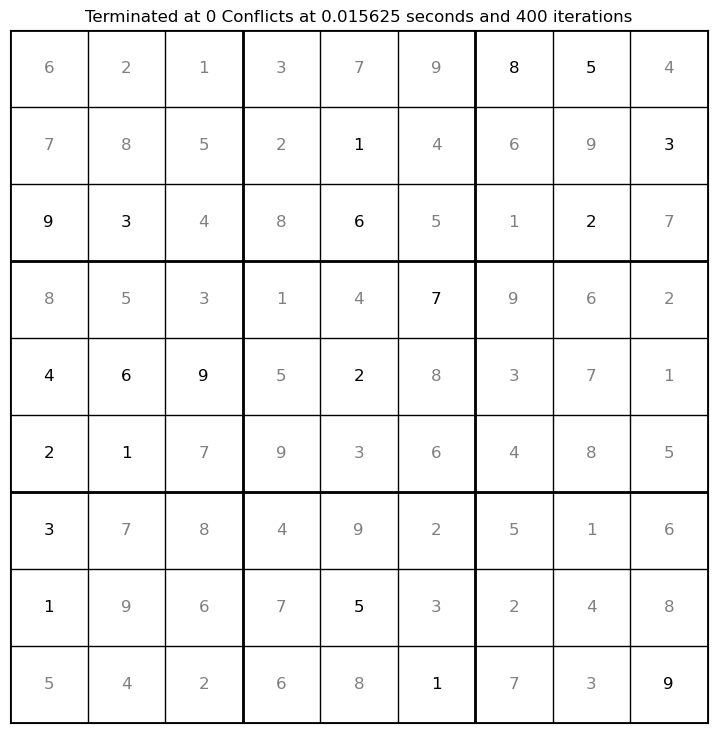

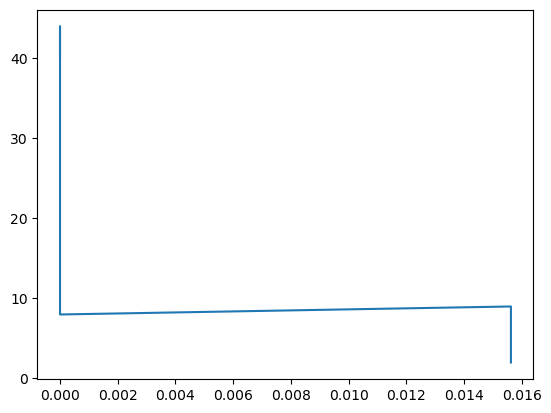

In [13]:
n = 9

puzzle, solution = generate_random_puzzle(size=n, num_clues= int(0.25*n**2))

# Determine fixed cells
fixed = {(i, j) for i in range(n) for j in range(n) if puzzle[i][j] != 0}

#plot_grid(puzzle,fixed_cells = fixed, title = f"Puzzle")

# Solve using SA
solved_grid, cost, iterations, duration, time_costs = run_simulated_annealing(puzzle, fixed, max_time = 60, verbose = True)

# Check if it solved
plot_grid(solved_grid,fixed_cells = fixed, title = f"Terminated at {cost} Conflicts at {duration} seconds and {iterations} iterations")

plt.plot(time_costs[:,0], time_costs[:,1])

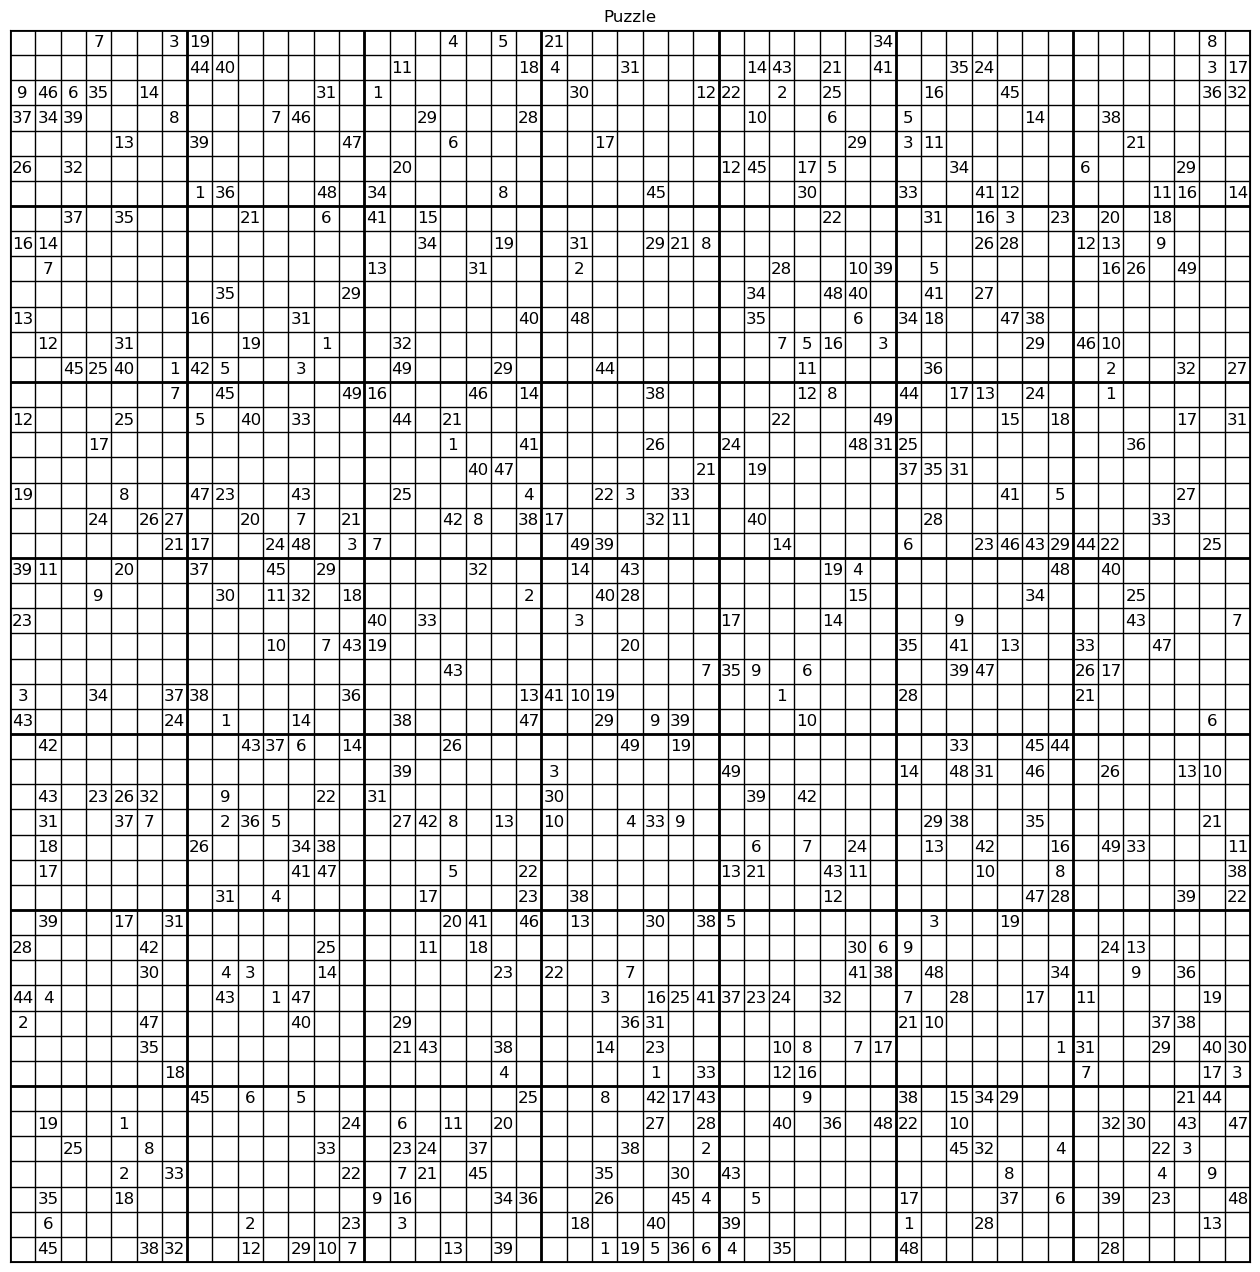

Running with VNS=False, Constructive=False
Running with VNS=False, Constructive=True
Running with VNS=True, Constructive=False
Running with VNS=True, Constructive=True


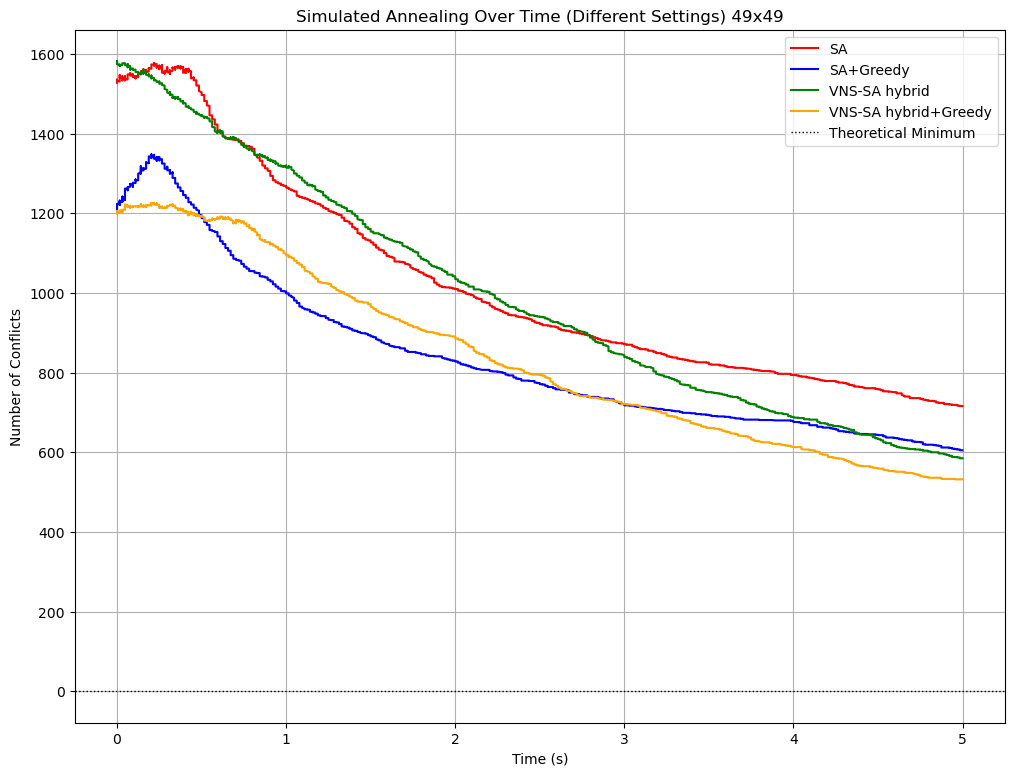

In [13]:
configs = [
    {"VNS": False, "constructive_candidate": False},
    {"VNS": False, "constructive_candidate": True},
    {"VNS": True,  "constructive_candidate": False},
    {"VNS": True,  "constructive_candidate": True},
]

labels = [
    "SA",
    "SA+Greedy",
    "VNS-SA hybrid",
    "VNS-SA hybrid+Greedy",
]

colors = ["red", "blue", "green", "orange"]
time_costs_list = []

# Generate puzzle once
n = 49
puzzle, solution = generate_random_puzzle(size=n, num_clues=int(0.25 * n**2), seed=2)
fixed = {(i, j) for i in range(n) for j in range(n) if puzzle[i][j] != 0}

# Plotting the puzzle for reference
plot_grid(puzzle, fixed_cells=fixed, title="Puzzle")
#plt.savefig('49x49 Grid puzzle tested')

# Run each configuration
for config in configs:
    print(f"Running with VNS={config['VNS']}, Constructive={config['constructive_candidate']}")
    _, _, _, _, time_costs = run_simulated_annealing(
        puzzle,
        fixed,
        max_time=5,
        verbose=False,
        VNS=config["VNS"],
        constructive_candidate=config["constructive_candidate"],
    )
    time_costs_list.append(time_costs)

# Plotting all on the same plot
plt.figure(figsize=(12, 9))
for i, time_costs in enumerate(time_costs_list):
    plt.plot(time_costs[:, 0], time_costs[:, 1], label=labels[i], color=colors[i])

plt.axhline(y=0, color='black', linestyle='dotted', linewidth=1, label='Theoretical Minimum')

plt.xlabel("Time (s)")
plt.ylabel("Number of Conflicts")
plt.title("Simulated Annealing Over Time (Different Settings) 49x49")
plt.legend()
plt.grid(True)
plt.savefig('Time vs Conflicts 49x49 first 5 secs.png')
plt.show()

Running benchmark: SA
Running benchmark: SA+Greedy
Running benchmark: VNS-SA hybrid
Running benchmark: VNS-SA hybrid
+Greedy
Running benchmark: ILP Solver
Saved table to: Benchmark Table 1000.png


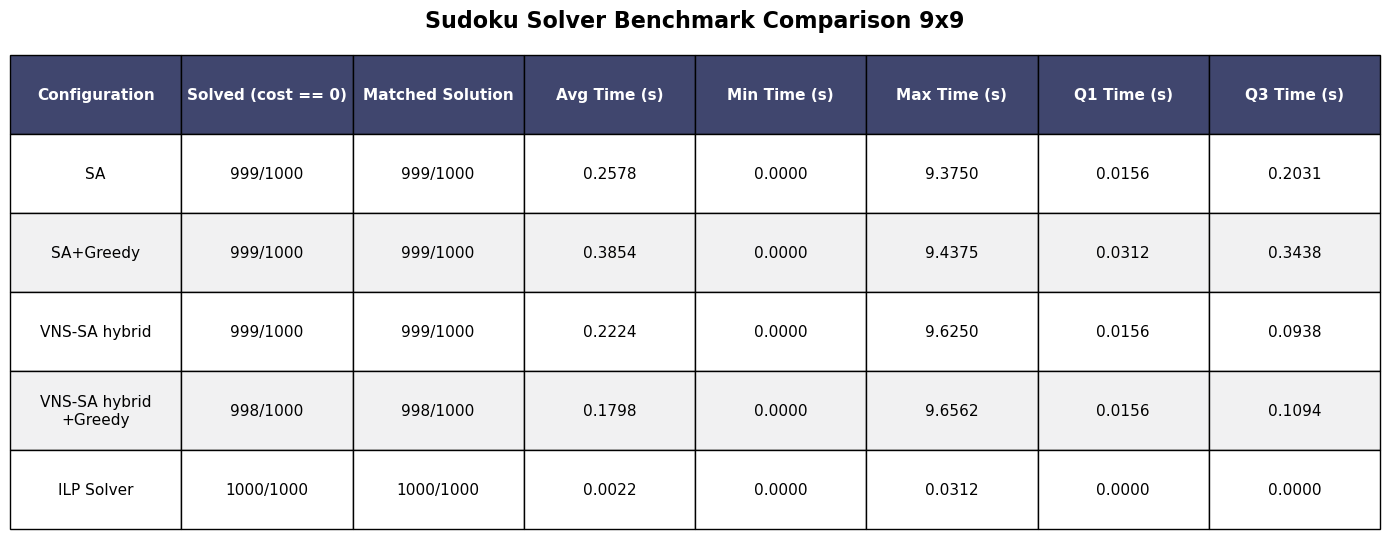

In [16]:
df_results = benchmark_all_configs_with_ilp_from_csv('sudoku.csv', n = 1000)
plot_benchmark_table(df_results, save_path = 'Benchmark Table 1000.png')